# Approach A — Classical consensus scoring (CAT / classical test theory)

Part of the approach series described in [`../APPROACHES.md`](../APPROACHES.md).

**Idea.** In Amabile's Consensual Assessment Technique (CAT), independent
judges rate each product and the product's score is the **average of the
judges' ratings**. Judges are treated as interchangeable, parallel measurements
of the same construct. Score quality is judged by **inter-rater agreement and
consistency**, not by modelling individual raters.

**This notebook computes**
- raw mean/median scores per action (with SE), plus a rater-mean-centred
  variant as a naive severity correction,
- pairwise rater agreement (exact/adjacent agreement, correlations, MAE,
  weighted kappa, Bland–Altman),
- Krippendorff's α (ordinal and interval) with a cluster bootstrap and
  subgroup sensitivity,
- the Spearman–Brown projection from single-rating reliability to the
  reliability of a k-rating mean,
- leave-one-rater-out consistency of every rater with the consensus of the others.

**Assumptions and limits.** Raters are assumed to be exchangeable. In this
incomplete design, different actions are rated by different raters, so a raw
mean mixes an action's creativity with the severity of whoever rated it; the
classical approach treats that as error. Rater-correcting alternatives are
Approaches B–D (`02b`–`02d`).

**Outputs:** `results/tables/scores_classical.csv`, `raters_classical.csv`,
`model_diagnostics_classical.csv`.

## 0. Setup, reproducibility, and session information

In [1]:
import warnings
import platform
import subprocess
import sys
import json
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

NOTEBOOK_KEY = "classical"
SEED = 20260713
np.random.seed(SEED)
rng = np.random.default_rng(SEED)

# ------------------------------------------------------------------
# Project paths (relative to the notebook folder "notebooks/")
# ------------------------------------------------------------------
PROJECT_ROOT = Path("..").resolve()
DATA_RAW = PROJECT_ROOT / "data" / "raw"
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"
RESULTS_TABLES = PROJECT_ROOT / "results" / "tables"
RESULTS_FIGURES = PROJECT_ROOT / "results" / "figures"
RESULTS_MODELS = PROJECT_ROOT / "results" / "models"
RESULTS_LOGS = PROJECT_ROOT / "results" / "logs"

for d in [DATA_PROCESSED, RESULTS_TABLES, RESULTS_FIGURES, RESULTS_MODELS, RESULTS_LOGS]:
    d.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 200
plt.rcParams["font.size"] = 10
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

warnings.filterwarnings("default", category=UserWarning)

def save_fig(fig, name, caption=None):
    # Saves a figure as PNG and SVG under results/figures/.
    fig.savefig(RESULTS_FIGURES / f"{name}.png", bbox_inches="tight")
    fig.savefig(RESULTS_FIGURES / f"{name}.svg", bbox_inches="tight")
    if caption:
        (RESULTS_FIGURES / f"{name}_caption.txt").write_text(caption)
    print(f"Figure saved: {name}.png / {name}.svg")

def save_table(df_table, name, index=False):
    # Saves a table as CSV under results/tables/.
    path = RESULTS_TABLES / f"{name}.csv"
    df_table.to_csv(path, index=index)
    print(f"Table saved: {path.relative_to(PROJECT_ROOT)} "
          f"({df_table.shape[0]} rows x {df_table.shape[1]} columns)")
    return path

def save_diagnostics(values):
    # Scalar results (reliability, convergence, ...) for 03_approach_comparison.ipynb.
    out = pd.DataFrame({"quantity": list(values), "value": [float(v) for v in values.values()]})
    return save_table(out, f"model_diagnostics_{NOTEBOOK_KEY}")

WARNINGS_LOG = []
def log_warning(msg):
    # No silent failures: warnings are collected and exported at the end of the notebook.
    WARNINGS_LOG.append({"notebook": NOTEBOOK_KEY,
                         "timestamp": datetime.now(timezone.utc).isoformat(),
                         "message": msg})
    warnings.warn(msg)

print(f"Seed: {SEED}")
print(f"Project root: {PROJECT_ROOT}")

Seed: 20260713
Project root: /home/max/drive/projects/3_Creativity/11-paper-CAT-methodology/data-analysis/creativity-ratings-psychometrics


In [2]:
def get_git_hash():
    try:
        out = subprocess.run(["git", "rev-parse", "HEAD"], cwd=PROJECT_ROOT,
                             capture_output=True, text=True, timeout=5)
        if out.returncode == 0:
            return out.stdout.strip()
    except Exception:
        pass
    return "not available"

session_info = {
    "notebook": NOTEBOOK_KEY,
    "analysis_datetime_utc": datetime.now(timezone.utc).isoformat(),
    "python_version": sys.version,
    "platform": platform.platform(),
    "git_commit": get_git_hash(),
    "seed": SEED,
    "package_versions": {},
}
for pkg_name in ['numpy', 'pandas', 'scipy', 'matplotlib', 'networkx', 'sklearn', 'krippendorff']:
    try:
        mod = __import__(pkg_name)
        session_info["package_versions"][pkg_name] = getattr(mod, "__version__", "unknown")
    except ImportError:
        session_info["package_versions"][pkg_name] = "not installed"

with open(RESULTS_LOGS / f"session_info_{NOTEBOOK_KEY}.json", "w") as f:
    json.dump(session_info, f, indent=2)
print(json.dumps(session_info["package_versions"], indent=2))

{
  "numpy": "2.4.6",
  "pandas": "3.0.3",
  "scipy": "1.18.0",
  "matplotlib": "3.11.0",
  "networkx": "3.6.1",
  "sklearn": "1.9.0",
  "krippendorff": "unknown"
}


## 1. Data

Loads the cleaned ratings from `00_data_loading_preprocessing.ipynb`
(`data/processed/ratings_long_clean.csv`) and flags the largest connected
component of the rater–action graph. This block is identical in all approach
notebooks so that each notebook runs on its own.

In [3]:
CLEAN_PATH = DATA_PROCESSED / "ratings_long_clean.csv"
if not CLEAN_PATH.exists():
    raise FileNotFoundError(f"{CLEAN_PATH} not found. Run 00_data_loading_preprocessing.ipynb first.")

ratings_clean = pd.read_csv(CLEAN_PATH)
ratings_clean["action_id"] = ratings_clean["action_id"].astype(str)
ratings_clean["rater_id"] = ratings_clean["rater_id"].astype(str)

required_cols = ["action_id", "rater_id", "rating_numeric"]
missing_cols = [c for c in required_cols if c not in ratings_clean.columns]
if missing_cols:
    raise ValueError(f"Required variables missing from the preprocessed dataset: {missing_cols}")
assert ratings_clean["rating_numeric"].between(1, 7).all(), "Ratings outside 1-7!"
assert not ratings_clean.duplicated(subset=["action_id", "rater_id"]).any(), "Duplicate (action_id, rater_id) rows!"

ratings_per_action = ratings_clean.groupby("action_id").size().rename("n_ratings")
n_raters = ratings_clean["rater_id"].nunique()
print(f"Loaded {len(ratings_clean)} ratings ({ratings_clean['action_id'].nunique()} actions, "
      f"{n_raters} raters).")
ratings_clean.head()

Loaded 7844 ratings (3669 actions, 22 raters).


,rater_id,action_id,rating,technical_correctness,aesthetic_appeal,timestamp,rating_numeric,rating_ordinal,rating_order
0,urst3254,0786bb62-2032-444b-ac1f-59fa165dbb71,1.0,2.0,2.0,2026-03-11 11:50:29.717,1,1,5
1,anma2416,f90addfa-4cf8-4b07-a4eb-9ee7ff757519,2.0,4.0,1.0,2025-11-18 12:26:15.275,2,2,708
2,anma2416,2bdc8133-ac12-45f1-9104-882873efa7bf,3.0,4.0,2.0,2025-10-15 13:35:18.000,3,3,17
3,azne2115,938d2c93-5e6f-442e-ba7c-f92c53080a42,5.0,5.0,5.0,2026-05-05 15:58:08.508,5,5,6
4,urst3254,4fe7a32b-09ce-466b-9772-494ed03ea493,6.0,7.0,7.0,2026-04-08 13:56:06.665,6,6,403


In [4]:
# Connected components of the bipartite rater-action graph. Rater severity is only
# identifiable within a component; full design diagnostics are in 01_data_overview.ipynb.
B = nx.Graph()
B.add_edges_from(zip(ratings_clean["action_id"], "R::" + ratings_clean["rater_id"]))
components = sorted(nx.connected_components(B), key=len, reverse=True)
n_components = len(components)

action_component_map = {n: i for i, comp in enumerate(components)
                        for n in comp if not str(n).startswith("R::")}
ratings_clean["connected_component"] = ratings_clean["action_id"].map(action_component_map)
ratings_clean["in_largest_component"] = ratings_clean["connected_component"] == 0
largest_component_actions = set(ratings_clean.loc[ratings_clean["in_largest_component"], "action_id"])
largest_component_raters = set(ratings_clean.loc[ratings_clean["in_largest_component"], "rater_id"])

print(f"Connected components: {n_components}; largest: {len(largest_component_actions)} actions, "
      f"{len(largest_component_raters)} raters.")
if n_components > 1:
    log_warning(f"The rater-action graph has {n_components} components; rater-correcting "
                "models are estimated on the largest one only.")

Connected components: 1; largest: 3669 actions, 22 raters.


## 2. Action scores: raw mean and rater-centred mean

### 2.1 Raw mean (the CAT score)

$$
\bar y_i = \frac{1}{n_i}\sum_j y_{ij}, \qquad SE(\bar y_i) = \frac{s_i}{\sqrt{n_i}}
$$

Transparent and assumption-light, but not corrected for rater severity, and
unstable for actions with few ratings. For actions with a single rating, no SE
can be computed (`NaN`).

### 2.2 Rater-centred mean (naive severity correction)

$$
y^{c}_{ij}=y_{ij}-\bar y_j+\bar y, \qquad
\bar y^{c}_{i}=\frac{1}{n_i}\sum_j y^{c}_{ij}
$$

This subtracts each rater's mean as a *fixed* severity effect. It is only
meaningful if raters rated comparable sets of actions: under selective
assignment, a low rater mean can reflect either strictness or a weaker set of
actions. The model-based version of this idea, which separates the two and
shrinks unstable estimates, is the linear mixed model in
`02b_linear_mixed_model.ipynb`. Here it is a descriptive sensitivity check only.

In [5]:
grand_mean = ratings_clean["rating_numeric"].mean()
rater_means = ratings_clean.groupby("rater_id")["rating_numeric"].mean()

ratings_clean["rating_rater_centered"] = (
    ratings_clean["rating_numeric"]
    - ratings_clean["rater_id"].map(rater_means)
    + grand_mean
)

action_scores = ratings_clean.groupby("action_id").agg(
    n_ratings=("rating_numeric", "size"),
    raw_mean=("rating_numeric", "mean"),
    raw_median=("rating_numeric", "median"),
    raw_sd=("rating_numeric", "std"),
    rater_centered_mean=("rating_rater_centered", "mean"),
    connected_component=("connected_component", "first"),
).reset_index()
action_scores["raw_se"] = action_scores["raw_sd"] / np.sqrt(action_scores["n_ratings"])

print(f"Action scores (raw/rater-centered) computed for {len(action_scores)} actions.")
action_scores.head()

Action scores (raw/rater-centered) computed for 3669 actions.


,action_id,n_ratings,raw_mean,raw_median,raw_sd,rater_centered_mean,connected_component,raw_se
0,0005dd54-38ba-4d89-bec8-7fce98a9fa87,2,3.5,3.5,2.121320,3.294148,0,1.5
1,001329ae-1d80-48b8-a47d-4c39234a3273,2,3.5,3.5,2.121320,3.837969,0,1.5
2,00134704-d2c8-401f-a874-e3d6d52832b0,2,1.0,1.0,0.000000,0.789951,0,0.0
3,001c7a5d-cb4d-4e7c-adbb-52a716b2b265,2,2.0,2.0,0.000000,1.954775,0,0.0
4,004d5af3-5523-46ed-aace-6bf0eb43a7bc,2,1.5,1.5,0.707107,1.961663,0,0.5


Figure saved: fig_classical_raw_vs_centered.png / fig_classical_raw_vs_centered.svg


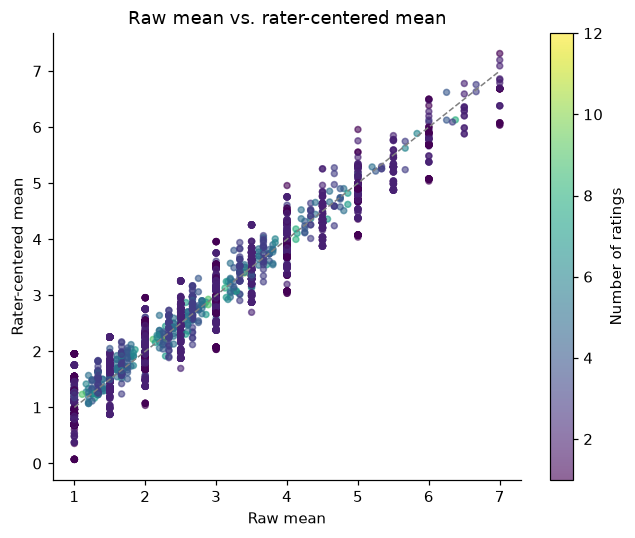

In [6]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(action_scores["raw_mean"], action_scores["rater_centered_mean"],
            c=action_scores["n_ratings"], cmap="viridis", s=15, alpha=0.6)
lims = [1, 7]
ax.plot(lims, lims, color="grey", ls="--", lw=1)
ax.set_xlabel("Raw mean")
ax.set_ylabel("Rater-centered mean")
ax.set_title("Raw mean vs. rater-centered mean")
cb = fig.colorbar(ax.collections[0], ax=ax)
cb.set_label("Number of ratings")
fig.tight_layout()
save_fig(fig, "fig_classical_raw_vs_centered",
         "Raw mean vs. rater-centered mean per action, colored by "
         "number of ratings.")
plt.show()

## 3. Pairwise agreement

For every rater pair with at least 10 jointly rated actions, we compute
**absolute agreement** (exact and adjacent [±1] agreement, mean difference,
MAE, quadratically weighted kappa) and **relative consistency** (Pearson,
Spearman, Kendall). A high correlation is compatible with a large systematic
mean difference, so agreement and consistency are reported separately.

In [7]:
from scipy import stats as sps
from sklearn.metrics import cohen_kappa_score

MIN_OVERLAP = 10

wide = ratings_clean.pivot_table(index="action_id", columns="rater_id",
                                    values="rating_numeric", aggfunc="first")

pair_stats = []
rater_list = wide.columns.tolist()
for i in range(len(rater_list)):
    for j in range(i + 1, len(rater_list)):
        rj, rk = rater_list[i], rater_list[j]
        both = wide[[rj, rk]].dropna()
        n_common = len(both)
        if n_common < MIN_OVERLAP:
            continue
        yj, yk = both[rj].values, both[rk].values
        pearson_r = np.corrcoef(yj, yk)[0, 1]
        spearman_r = sps.spearmanr(yj, yk).correlation
        kendall_t = sps.kendalltau(yj, yk).correlation
        mean_diff = yj.mean() - yk.mean()
        sd_diff = (yj - yk).std(ddof=1)
        mae = np.abs(yj - yk).mean()
        w_kappa = cohen_kappa_score(yj, yk, weights="quadratic")
        exact_agree = np.mean(yj == yk)
        adjacent_agree = np.mean(np.abs(yj - yk) <= 1)
        pair_stats.append({
            "rater_1": rj, "rater_2": rk, "n_common_actions": n_common,
            "exact_agreement": exact_agree, "adjacent_agreement": adjacent_agree,
            "pearson_r": pearson_r, "spearman_r": spearman_r, "kendall_tau": kendall_t,
            "mean_diff_1_minus_2": mean_diff, "sd_diff": sd_diff, "mae": mae,
            "weighted_kappa": w_kappa,
        })

pair_stats_df = pd.DataFrame(pair_stats)
save_table(pair_stats_df, "pairwise_rater_agreement")
print(f"Rater pairs with >= {MIN_OVERLAP} shared actions: {len(pair_stats_df)} "
      f"out of {n_raters * (n_raters - 1) // 2} possible pairs")
pair_stats_df.describe()

Table saved: results/tables/pairwise_rater_agreement.csv (101 rows x 12 columns)
Rater pairs with >= 10 shared actions: 101 out of 231 possible pairs


,n_common_actions,exact_agreement,adjacent_agreement,pearson_r,spearman_r,kendall_tau,mean_diff_1_minus_2,sd_diff,mae,weighted_kappa
count,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000
mean,65.247525,0.268724,0.652237,0.473690,0.467675,0.396753,0.114411,1.459700,1.276592,0.398457
std,68.902744,0.115618,0.133209,0.182701,0.184655,0.162541,0.862509,0.278965,0.337450,0.174590
min,10.000000,0.000000,0.305556,-0.126743,-0.126247,-0.084515,-1.652174,0.867793,0.625000,-0.092437
25%,19.000000,0.192308,0.558621,0.367198,0.378433,0.320332,-0.600000,1.277636,1.055556,0.293680
50%,44.000000,0.280000,0.680000,0.497619,0.486246,0.408196,0.076923,1.450758,1.200000,0.420601
75%,74.000000,0.354839,0.744681,0.615671,0.593644,0.516326,0.788462,1.613238,1.500000,0.544643
max,357.000000,0.562500,0.884615,0.820922,0.817798,0.755610,1.967532,2.239893,2.055556,0.767857


### 3.1 Bland–Altman-style plot

For the two rater pairs with the largest overlap: mean vs. difference
of the two ratings, mean difference, and limits of agreement
($\pm 1.96 \cdot SD_{\text{diff}}$). The Likert scale is discrete and
bounded — this plot is diagnostic, not the sole basis for inference
(overplotting is mitigated via jitter and point-size encoding of
frequency).

Figure saved: fig_classical_bland_altman_top_pairs.png / fig_classical_bland_altman_top_pairs.svg


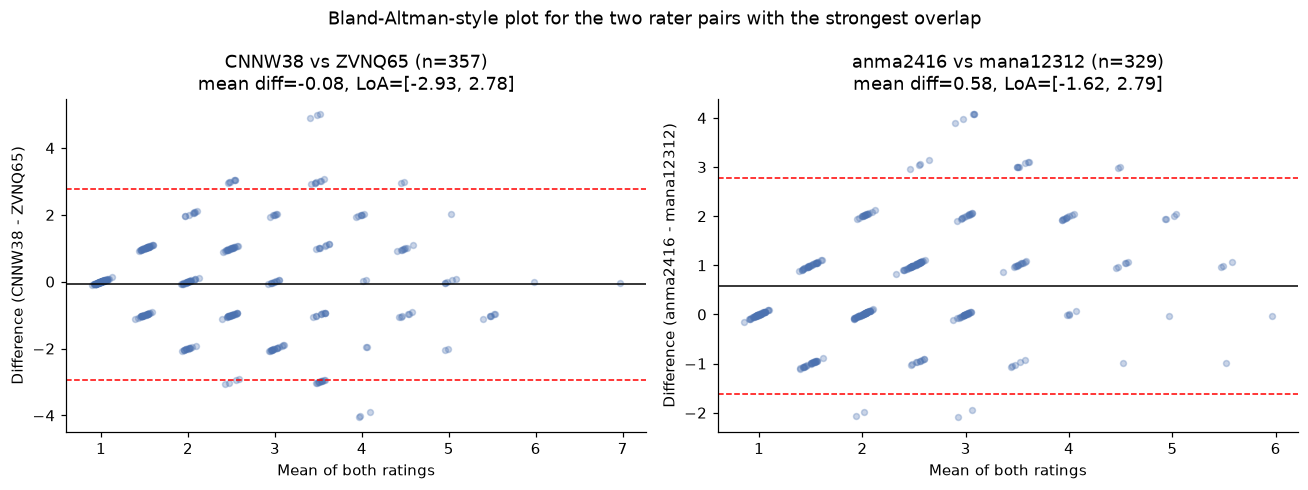

In [8]:
top_pairs = pair_stats_df.nlargest(2, "n_common_actions")

fig, axes = plt.subplots(1, len(top_pairs), figsize=(6 * len(top_pairs), 4.5))
if len(top_pairs) == 1:
    axes = [axes]
for ax, (_, row) in zip(axes, top_pairs.iterrows()):
    rj, rk = row["rater_1"], row["rater_2"]
    both = wide[[rj, rk]].dropna()
    mean_ = both.mean(axis=1)
    diff_ = both[rj] - both[rk]
    jitter = rng.normal(0, 0.05, size=len(both))
    ax.scatter(mean_ + jitter, diff_ + jitter, alpha=0.3, s=15, color="#4C72B0")
    md_ = diff_.mean()
    sd_ = diff_.std(ddof=1)
    ax.axhline(md_, color="black", lw=1)
    ax.axhline(md_ + 1.96 * sd_, color="red", ls="--", lw=1)
    ax.axhline(md_ - 1.96 * sd_, color="red", ls="--", lw=1)
    ax.set_title(f"{rj} vs {rk} (n={len(both)})\nmean diff={md_:.2f}, LoA=[{md_-1.96*sd_:.2f}, {md_+1.96*sd_:.2f}]")
    ax.set_xlabel("Mean of both ratings")
    ax.set_ylabel(f"Difference ({rj} - {rk})")
fig.suptitle("Bland-Altman-style plot for the two rater pairs with the strongest overlap")
fig.tight_layout()
save_fig(fig, "fig_classical_bland_altman_top_pairs",
         "Bland-Altman-style plots (with jitter due to the discrete scale) for "
         "the two rater pairs with the largest number of jointly rated actions.")
plt.show()

### 3.2 Rater-pair heatmaps

Separate heatmaps for shared actions, Spearman correlation, mean
difference, and weighted kappa. Rater pairs with insufficient overlap
($n < 10$) are masked (grey).

Figure saved: fig_classical_pairwise_heatmaps.png / fig_classical_pairwise_heatmaps.svg


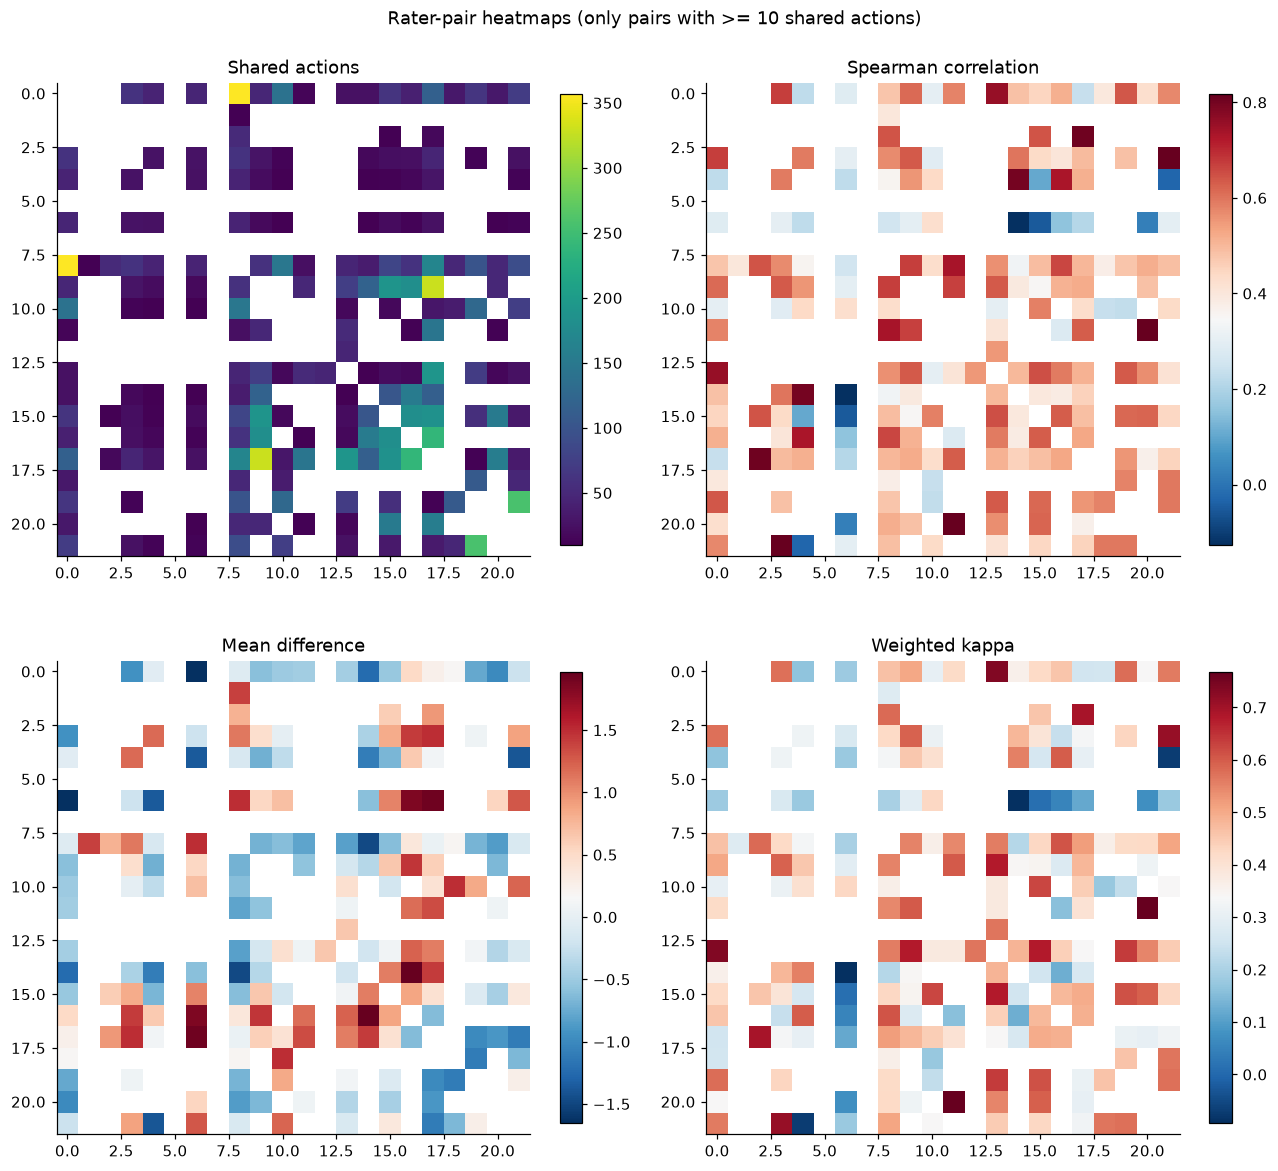

In [9]:
def pair_matrix(metric_col):
    mat = pd.DataFrame(np.nan, index=rater_list, columns=rater_list)
    for _, row in pair_stats_df.iterrows():
        mat.loc[row["rater_1"], row["rater_2"]] = row[metric_col]
        mat.loc[row["rater_2"], row["rater_1"]] = row[metric_col]
    return mat

fig, axes = plt.subplots(2, 2, figsize=(12, 11))
metrics = [("n_common_actions", "Shared actions", "viridis"),
           ("spearman_r", "Spearman correlation", "RdBu_r"),
           ("mean_diff_1_minus_2", "Mean difference", "RdBu_r"),
           ("weighted_kappa", "Weighted kappa", "RdBu_r")]
for ax, (col, title, cmap) in zip(axes.flat, metrics):
    mat = pair_matrix(col)
    masked = np.ma.masked_invalid(mat.values)
    im = ax.imshow(masked, cmap=cmap)
    ax.set_title(title)
    fig.colorbar(im, ax=ax, shrink=0.8)
fig.suptitle(f"Rater-pair heatmaps (only pairs with >= {MIN_OVERLAP} shared actions)")
fig.tight_layout()
save_fig(fig, "fig_classical_pairwise_heatmaps",
         "Heatmaps of pairwise agreement metrics between raters; "
         "masked (white) cells = insufficient overlap.")
plt.show()

## 4. Krippendorff's alpha

### Why Krippendorff's alpha?

Krippendorff's $\alpha$ fundamentally supports differing numbers of
raters per unit, missing ratings, more than two raters, and different
levels of measurement — all properties of the present design. We
compute:

1. **ordinal alpha** (primary — category distances are not assumed to
   be exactly equal),
2. **interval-scaled alpha** as a sensitivity analysis.

$$
\alpha = 1 - \frac{D_o}{D_e}
$$

where $D_o$ is the observed and $D_e$ the expected disagreement
(under random assignment), weighted by a distance function $\delta$
that depends on the level of measurement.

**Data shape:** The `krippendorff` package expects a reliability-data
matrix shaped (raters × units) with `NaN` for missing combinations —
we therefore transpose `wide` (actions × raters) accordingly.

In [10]:
import krippendorff as kd

reliability_data = wide.T.values  # (raters x actions), NaN = missing

alpha_ordinal = kd.alpha(reliability_data=reliability_data,
                           level_of_measurement="ordinal")
alpha_interval = kd.alpha(reliability_data=reliability_data,
                            level_of_measurement="interval")

print(f"Krippendorff's alpha (ordinal, primary):        {alpha_ordinal:.3f}")
print(f"Krippendorff's alpha (interval, sensitivity):    {alpha_interval:.3f}")

Krippendorff's alpha (ordinal, primary):        0.391
Krippendorff's alpha (interval, sensitivity):    0.418


### 4.1 Uncertainty: cluster bootstrap over actions

The action is the primary unit of observation. In the bootstrap,
**all ratings of a sampled action stay together** (cluster bootstrap
over actions, not naive resampling of individual ratings). We use
2,000 bootstrap replications with a fixed seed.

In [11]:
N_BOOT = 2000
action_ids_all = wide.index.to_numpy()
n_actions_all = len(action_ids_all)

boot_rng = np.random.default_rng(SEED)
boot_alphas_ord = np.empty(N_BOOT)
boot_alphas_int = np.empty(N_BOOT)

for b in range(N_BOOT):
    sampled_actions = boot_rng.choice(action_ids_all, size=n_actions_all, replace=True)
    boot_wide = wide.loc[sampled_actions]
    rel_data = boot_wide.T.values
    try:
        boot_alphas_ord[b] = kd.alpha(reliability_data=rel_data, level_of_measurement="ordinal")
        boot_alphas_int[b] = kd.alpha(reliability_data=rel_data, level_of_measurement="interval")
    except Exception:
        boot_alphas_ord[b] = np.nan
        boot_alphas_int[b] = np.nan

ci_ord = np.nanpercentile(boot_alphas_ord, [2.5, 97.5])
ci_int = np.nanpercentile(boot_alphas_int, [2.5, 97.5])
print(f"Ordinal alpha:  {alpha_ordinal:.3f}, 95% cluster-bootstrap CI [{ci_ord[0]:.3f}, {ci_ord[1]:.3f}] "
      f"(n_boot={N_BOOT}, {np.isnan(boot_alphas_ord).sum()} failed replications)")
print(f"Interval alpha: {alpha_interval:.3f}, 95% cluster-bootstrap CI [{ci_int[0]:.3f}, {ci_int[1]:.3f}]")

Ordinal alpha:  0.391, 95% cluster-bootstrap CI [0.362, 0.420] (n_boot=2000, 0 failed replications)
Interval alpha: 0.418, 95% cluster-bootstrap CI [0.388, 0.448]


### 4.2 Subgroup and sensitivity analyses

Alpha additionally for: actions with ≥2 ratings, actions with ≥3
ratings, and within the largest connected component.
**Warning:** alpha values from different subsets are not directly
comparable, since the heterogeneity of the included actions differs.

In [12]:
def alpha_for_subset(action_subset, label):
    sub_wide = wide.loc[wide.index.isin(action_subset)]
    rel = sub_wide.T.values
    a_ord = kd.alpha(reliability_data=rel, level_of_measurement="ordinal")
    a_int = kd.alpha(reliability_data=rel, level_of_measurement="interval")
    return {"subset": label, "n_actions": len(sub_wide),
            "alpha_ordinal": a_ord, "alpha_interval": a_int}

subset_results = [
    alpha_for_subset(wide.index, "all actions"),
    alpha_for_subset(ratings_per_action[ratings_per_action >= 2].index, "n_ratings >= 2"),
    alpha_for_subset(ratings_per_action[ratings_per_action >= 3].index, "n_ratings >= 3"),
    alpha_for_subset(ratings_per_action[ratings_per_action >= 4].index, "n_ratings >= 4"),
    alpha_for_subset(ratings_per_action[ratings_per_action >= 5].index, "n_ratings >= 5"),
    alpha_for_subset(largest_component_actions, "largest connected component"),
]
subset_results_df = pd.DataFrame(subset_results)
save_table(subset_results_df, "krippendorff_alpha_sensitivity")
print(subset_results_df)

alpha_summary_df = pd.DataFrame([{
    "measure": "ordinal", "alpha": alpha_ordinal, "ci_low": ci_ord[0], "ci_high": ci_ord[1],
    "n_boot": N_BOOT,
}, {
    "measure": "interval", "alpha": alpha_interval, "ci_low": ci_int[0], "ci_high": ci_int[1],
    "n_boot": N_BOOT,
}])
save_table(alpha_summary_df, "krippendorff_alpha_main")

log_warning(
    "Krippendorff's alpha values from different subsets (e.g. >=2 vs. >=3 ratings) "
    "are not directly comparable due to differing action heterogeneity."
)

Table saved: results/tables/krippendorff_alpha_sensitivity.csv (6 rows x 4 columns)
                        subset  n_actions  alpha_ordinal  alpha_interval
0                  all actions       3669       0.390649        0.418132
1               n_ratings >= 2       2771       0.390649        0.418132
2               n_ratings >= 3        691       0.372040        0.397075
3               n_ratings >= 4        334       0.385053        0.403081
4               n_ratings >= 5        211       0.359573        0.371857
5  largest connected component       3669       0.390649        0.418132
Table saved: results/tables/krippendorff_alpha_main.csv (2 rows x 5 columns)


/tmp/ipykernel_166882/898367390.py:68: UserWarning: Krippendorff's alpha values from different subsets (e.g. >=2 vs. >=3 ratings) are not directly comparable due to differing action heterogeneity.
  warnings.warn(msg)


### 4.3 From single ratings to scores: Spearman–Brown projection

α describes the reliability of a **single rating**. Interval-level α is close
to the one-way intraclass correlation ICC(1), in which rater differences count
as error, the classical counterpart of the absolute coefficient Φ in
generalizability theory (`02b`). Assuming exchangeable raters, the reliability
of the **mean of k ratings** follows from the Spearman–Brown formula:

$$
\rho_k = \frac{k\,\alpha}{1+(k-1)\,\alpha}
$$

We evaluate it at k = 1…10, at the median number of ratings per action, and
at the harmonic mean of the number of ratings. The harmonic mean is the
effective k for the mean reliability of unequal-n means. Credible intervals
apply the formula to every bootstrap replicate from 4.1.

Ratings per action: median = 2.0, harmonic mean = 1.73
Table saved: results/tables/classical_spearman_brown.csv (24 rows x 6 columns)


Figure saved: fig_classical_spearman_brown.png / fig_classical_spearman_brown.svg


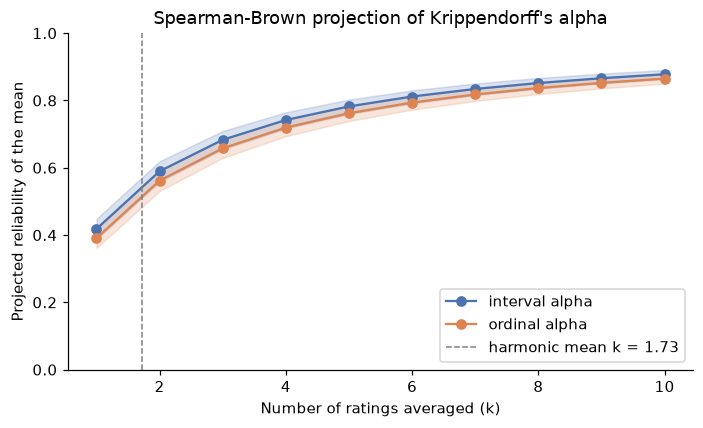

,k_label,k,alpha_level,reliability,ci_low,ci_high
0,k=1,1.00000,interval,0.418132,0.387665,0.448397
1,k=1,1.00000,ordinal,0.390649,0.361535,0.419589
20,k=median,2.00000,interval,0.589694,0.558730,0.619163
21,k=median,2.00000,ordinal,0.561823,0.531070,0.591141
22,k=harmonic mean,1.72632,interval,0.553678,0.522199,0.583909
23,k=harmonic mean,1.72632,ordinal,0.525330,0.494321,0.555157


In [13]:
def spearman_brown(rel_1, k):
    return k * rel_1 / (1 + (k - 1) * rel_1)

k_median = float(ratings_per_action.median())
k_harmonic = float(len(ratings_per_action) / (1.0 / ratings_per_action).sum())
print(f"Ratings per action: median = {k_median:.1f}, harmonic mean = {k_harmonic:.2f}")

k_values = [(f"k={k}", float(k)) for k in range(1, 11)]
k_values += [("k=median", k_median), ("k=harmonic mean", k_harmonic)]

sb_rows = []
for label, k in k_values:
    for level, a_point, a_boot in [("interval", alpha_interval, boot_alphas_int),
                                   ("ordinal", alpha_ordinal, boot_alphas_ord)]:
        boot_k = spearman_brown(a_boot[~np.isnan(a_boot)], k)
        sb_rows.append({"k_label": label, "k": k, "alpha_level": level,
                        "reliability": spearman_brown(a_point, k),
                        "ci_low": np.percentile(boot_k, 2.5),
                        "ci_high": np.percentile(boot_k, 97.5)})
spearman_brown_df = pd.DataFrame(sb_rows)
save_table(spearman_brown_df, "classical_spearman_brown")

fig, ax = plt.subplots(figsize=(6.5, 4))
for level, color in [("interval", "#4C72B0"), ("ordinal", "#DD8452")]:
    sub = spearman_brown_df[(spearman_brown_df["alpha_level"] == level)
                            & spearman_brown_df["k_label"].str.match(r"k=\d")]
    ax.plot(sub["k"], sub["reliability"], marker="o", color=color, label=f"{level} alpha")
    ax.fill_between(sub["k"], sub["ci_low"], sub["ci_high"], color=color, alpha=0.2)
ax.axvline(k_harmonic, color="grey", ls="--", lw=1, label=f"harmonic mean k = {k_harmonic:.2f}")
ax.set_xlabel("Number of ratings averaged (k)")
ax.set_ylabel("Projected reliability of the mean")
ax.set_ylim(0, 1)
ax.set_title("Spearman-Brown projection of Krippendorff's alpha")
ax.legend()
fig.tight_layout()
save_fig(fig, "fig_classical_spearman_brown",
         "Spearman-Brown projection of Krippendorff's alpha (interval and ordinal) to the "
         "reliability of a k-rating mean, with 95% cluster-bootstrap bands.")
plt.show()
spearman_brown_df[spearman_brown_df["k_label"].isin(["k=1", "k=median", "k=harmonic mean"])]

## 5. Rater consistency: leave-one-rater-out

For every action with $n_i \ge 2$ ratings, we compute the **consensus without
rater $j$** (mean of the other ratings) and compare rater $j$'s rating with it.
Excluding the rater avoids the circularity of comparing a rater to a consensus
that contains their own rating. This is the judge-level analogue of the
corrected item–total correlation in classical test theory. The model-based
counterparts are the infit/outfit statistics in `02c` and the JRT
discrimination in `02d`.

In [14]:
ratings_indexed = ratings_clean.set_index(["action_id", "rater_id"])["rating_numeric"]
action_sum = ratings_clean.groupby("action_id")["rating_numeric"].sum()
action_n = ratings_clean.groupby("action_id")["rating_numeric"].size()

tmp = ratings_clean.copy()
tmp["_action_sum"] = tmp["action_id"].map(action_sum)
tmp["_action_n"] = tmp["action_id"].map(action_n)
tmp["loo_consensus"] = np.where(
    tmp["_action_n"] >= 2,
    (tmp["_action_sum"] - tmp["rating_numeric"]) / (tmp["_action_n"] - 1),
    np.nan,
)

def loo_stats(g):
    valid = g.dropna(subset=["loo_consensus"])
    if len(valid) < 5:
        return pd.Series({"leave_one_out_spearman": np.nan, "leave_one_out_mae": np.nan,
                            "leave_one_out_mean_diff": np.nan, "leave_one_out_weighted_kappa": np.nan,
                            "n_loo": len(valid)})
    spearman_r = sps.spearmanr(valid["rating_numeric"], valid["loo_consensus"]).correlation
    mae = np.abs(valid["rating_numeric"] - valid["loo_consensus"]).mean()
    mean_diff = (valid["rating_numeric"] - valid["loo_consensus"]).mean()
    loo_rounded = valid["loo_consensus"].round().clip(1, 7).astype(int)
    w_kappa = cohen_kappa_score(valid["rating_numeric"], loo_rounded, weights="quadratic")
    return pd.Series({"leave_one_out_spearman": spearman_r, "leave_one_out_mae": mae,
                        "leave_one_out_mean_diff": mean_diff,
                        "leave_one_out_weighted_kappa": w_kappa, "n_loo": len(valid)})

loo_df = tmp.groupby("rater_id").apply(loo_stats, include_groups=False).reset_index()
save_table(loo_df, "leave_one_out_consistency")
print(f"Leave-one-out consistency computed for {loo_df['leave_one_out_spearman'].notna().sum()} "
      f"of {len(loo_df)} raters (remainder: too few actions with >=2 ratings).")
loo_df.sort_values("leave_one_out_spearman").head(10)

Table saved: results/tables/leave_one_out_consistency.csv (22 rows x 6 columns)
Leave-one-out consistency computed for 21 of 22 raters (remainder: too few actions with >=2 ratings).


,rater_id,leave_one_out_spearman,leave_one_out_mae,leave_one_out_mean_diff,leave_one_out_weighted_kappa,n_loo
7,XIIO87,-0.049417,1.434253,0.659497,-0.024390,8.0
6,VMBX49,0.304545,1.483445,1.154953,0.252231,55.0
10,azne2115,0.320330,1.696421,0.898875,0.294932,326.0
17,mana12312,0.425715,1.067565,-0.632965,0.403448,1112.0
14,clpe1410,0.478714,1.438831,1.232177,0.297328,248.0
9,anma2416,0.479506,0.985475,0.393900,0.455296,634.0
18,nayü2116,0.482533,1.333286,-0.916620,0.430883,202.0
19,nedu1581,0.485626,1.301259,0.152042,0.485515,626.0
4,PDAR89,0.508683,1.008364,-0.477167,0.416541,52.0
13,chra3054,0.511064,1.136832,0.346832,0.510074,490.0


## 6. Export in the standard format

`scores_classical.csv` uses the raw mean as `score`. The 95% interval is
mean ± 1.96·SE, and is `NaN` for single-rating actions. With only 2–3 ratings, this
normal-theory interval is very wide and can extend beyond 1–7. It is left
unclipped as an honest statement of how little a 2-rating mean pins down. `raters_classical.csv`
uses the naive severity (rater mean − grand mean; positive = more lenient),
plus pairwise and leave-one-out consistency.

In [15]:
scores_classical = action_scores.copy()
scores_classical["in_largest_component"] = scores_classical["connected_component"] == 0
scores_classical["score"] = scores_classical["raw_mean"]
scores_classical["score_se"] = scores_classical["raw_se"]
scores_classical["score_lower"] = scores_classical["score"] - 1.96 * scores_classical["score_se"]
scores_classical["score_upper"] = scores_classical["score"] + 1.96 * scores_classical["score_se"]
scores_classical = scores_classical[[
    "action_id", "n_ratings", "connected_component", "in_largest_component",
    "score", "score_se", "score_lower", "score_upper",
    "raw_mean", "raw_median", "raw_sd", "raw_se", "rater_centered_mean",
]]
save_table(scores_classical, "scores_classical")

raters_classical = (ratings_clean.groupby("rater_id")["rating_numeric"]
                    .agg(n_ratings="size", rater_mean="mean", rater_sd="std").reset_index())
raters_classical["severity"] = raters_classical["rater_mean"] - grand_mean
raters_classical["severity_se"] = raters_classical["rater_sd"] / np.sqrt(raters_classical["n_ratings"])
raters_classical["severity_lower"] = raters_classical["severity"] - 1.96 * raters_classical["severity_se"]
raters_classical["severity_upper"] = raters_classical["severity"] + 1.96 * raters_classical["severity_se"]

pair_long = pd.concat([
    pair_stats_df.rename(columns={"rater_1": "rater_id"}),
    pair_stats_df.rename(columns={"rater_2": "rater_id"}),
])
pair_summary = (pair_long.groupby("rater_id")
                .agg(mean_pairwise_weighted_kappa=("weighted_kappa", "mean"),
                     mean_pairwise_spearman=("spearman_r", "mean"),
                     mean_exact_agreement=("exact_agreement", "mean"),
                     n_pairs_evaluated=("weighted_kappa", "size"))
                .reset_index())
raters_classical = (raters_classical.merge(pair_summary, on="rater_id", how="left")
                    .merge(loo_df, on="rater_id", how="left"))
save_table(raters_classical, "raters_classical")

sb = spearman_brown_df.set_index(["k_label", "alpha_level"])
save_diagnostics({
    "alpha_ordinal": alpha_ordinal, "alpha_ordinal_ci_low": ci_ord[0], "alpha_ordinal_ci_high": ci_ord[1],
    "alpha_interval": alpha_interval, "alpha_interval_ci_low": ci_int[0], "alpha_interval_ci_high": ci_int[1],
    "n_boot": N_BOOT,
    "k_median": k_median, "k_harmonic": k_harmonic,
    "sb_interval_k_harmonic": sb.loc[("k=harmonic mean", "interval"), "reliability"],
    "sb_ordinal_k_harmonic": sb.loc[("k=harmonic mean", "ordinal"), "reliability"],
    "n_rater_pairs_evaluated": len(pair_stats_df),
    "median_pairwise_weighted_kappa": pair_stats_df["weighted_kappa"].median(),
    "median_exact_agreement": pair_stats_df["exact_agreement"].median(),
    "median_adjacent_agreement": pair_stats_df["adjacent_agreement"].median(),
    "n_components": n_components,
    "n_single_rating_actions": int((ratings_per_action == 1).sum()),
})

Table saved: results/tables/scores_classical.csv (3669 rows x 13 columns)
Table saved: results/tables/raters_classical.csv (22 rows x 17 columns)
Table saved: results/tables/model_diagnostics_classical.csv (17 rows x 2 columns)


PosixPath('/home/max/drive/projects/3_Creativity/11-paper-CAT-methodology/data-analysis/creativity-ratings-psychometrics/results/tables/model_diagnostics_classical.csv')

## Warnings collected in this notebook

In [16]:
warnings_df = pd.DataFrame(WARNINGS_LOG, columns=["notebook", "timestamp", "message"])
save_table(warnings_df, f"warnings_log_{NOTEBOOK_KEY}")
print(f"{len(warnings_df)} warnings collected in this notebook.")
for msg in warnings_df["message"]:
    print(f"  - {msg}")

Table saved: results/tables/warnings_log_classical.csv (1 rows x 3 columns)
1 warnings collected in this notebook.
  - Krippendorff's alpha values from different subsets (e.g. >=2 vs. >=3 ratings) are not directly comparable due to differing action heterogeneity.
